
# PR1 — Limpieza, EDA y visualización de *logs* de seguridad

**Estudiante:** _Astudillo Soriano, Johnny_  

**Fecha:** _2026-11-01_  

**Dataset:** `data/PR1_security_logs_Mar2025.csv`


## Objetivos y entregables

- Tratar datos de ciberseguridad: **ingesta → limpieza → normalización → EDA → visualización → detección de campañas → informe**.
- Usar `pandas`/`numpy` y graficar con `matplotlib` o `plotly`.
- Entregar:
  - `notebook/PR1_<apellidos>_<nombre>.ipynb` (este cuaderno completado)
  - `informe/informe_PR1_<apellidos>_<nombre>.pdf` (máx. 5 páginas)
  - `resultados/figuras/*.png|.html`
  - `resultados/eventos_flagged.csv`
  - `data/PR1_security_logs_Mar2025.csv`
  - `requirements.txt` o `environment.yml`


### Python Built-in libraries

In [1]:

# === Built-in imports ===
import re
import ipaddress
from datetime import datetime, timezone
import ipaddress
from typing import Any


### Third Party imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

### Global constants

In [3]:
# === Colors for enhanced outputs ===
GREEN = "\033[0;32m"
GREEN_BOLD = "\033[1;32m"
BOLD = "\033[1m"
RESET = "\033[0m"

In [4]:
print(
    f"{GREEN}pandas {pd.__version__}{RESET} | {GREEN}numpy {np.__version__}{RESET} | {GREEN}matplotlib {matplotlib.__version__}{RESET}"
)

pandas 3.1.0 | numpy 2.5.4 | matplotlib 3.11.2


### Project pre-configuration

In [5]:

# === Configuración de entorno y rutas ===
from pathlib import Path

# Rutas base del proyecto (asume estructura de la plantilla)
BASE = Path().cwd().parent
DATA = BASE / "data" / "PR1_security_logs_Mar2025.csv"
OUT_DIR = BASE / "resultados"
FIG_DIR = OUT_DIR / "figuras"

# Crea carpetas de salida si no existen
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Semilla opcional (para reproducibilidad en muestreos, etc.)
SEED = 42

print("BASE:", BASE)
print("DATA:", DATA)
print("OUT_DIR:", OUT_DIR)
print("FIG_DIR:", FIG_DIR)


BASE: /Users/uoc/Developer/PR1_Astudillo_Soriano_Johnny
DATA: /Users/uoc/Developer/PR1_Astudillo_Soriano_Johnny/data/PR1_security_logs_Mar2025.csv
OUT_DIR: /Users/uoc/Developer/PR1_Astudillo_Soriano_Johnny/resultados
FIG_DIR: /Users/uoc/Developer/PR1_Astudillo_Soriano_Johnny/resultados/figuras


### Pandas configuration

In [6]:
pd.set_option('display.max_columns', None)

### Global functions

In [7]:
def save_figure(fig_name: str) -> None:
    """
    Saves the active figure in results/figures.

    Parameters
    ----------
    fig_name : str
        Name of the figure file to save.
    """
    assert fig_name, "Especifica un nombre para la figura, p.ej. 'req_por_dia.png'"
    path = FIG_DIR / fig_name
    plt.savefig(path, bbox_inches="tight", dpi=120)
    print("Figura guardada en:", path)



---
## Etapa A — Ingesta y *profiling* inicial

**Tareas:**  
- Carga el CSV en un `DataFrame` `df`.  
- Explora `shape`, `info()`, `describe()`, ejemplos de filas (`head()`, `tail()`).  
- Identifica tipos esperados vs reales; localiza nulos y valores inválidos (timestamps imposibles, IPs malformadas, `bytes_sent` vacíos).  
- Busca duplicados relevantes (decide la clave: ¿`event_id` único? ¿tupla clave?).

**Recomendaciones:**  
- Usa `pd.read_csv(..., low_memory=False)` si ves *dtypes* mezclados.  
- Declara `na_values=["", "-"]` si procede.  
- Documenta DECISIONES de limpieza que anticipas.


### Dataset Loading

In [8]:
# === Data Loading ===
df = pd.read_csv(DATA, low_memory=False, na_values=["", "-"]) # na_values used to convert empty strings and "-" to NaN

### Dataset Profiling

In [9]:
print(f"{GREEN_BOLD}Dataset shape:{RESET} {df.shape}")

Dataset shape: (11775, 24)


In [10]:
print(f"{GREEN_BOLD}General info:{RESET}")
df.info(verbose=True, memory_usage=False, show_counts=True)

General info:
<class 'pandas.DataFrame'>
RangeIndex: 11775 entries, 0 to 11774
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   event_id          11775 non-null  int64  
 1   timestamp         11744 non-null  str    
 2   src_ip            11775 non-null  str    
 3   src_port          11775 non-null  int64  
 4   src_country       11775 non-null  str    
 5   dest_ip           11775 non-null  str    
 6   dest_port         11775 non-null  int64  
 7   host              11775 non-null  str    
 8   http_method       11775 non-null  str    
 9   url_path          11775 non-null  str    
 10  query_string      2984 non-null   str    
 11  status            11775 non-null  int64  
 12  bytes_sent        11394 non-null  float64
 13  referrer          7795 non-null   str    
 14  user_agent        11775 non-null  str    
 15  protocol          11775 non-null  str    
 16  http_version      11775 non-null  flo

Con este pequeño análisis podemos observar que existen columnas con valores nulos a los que prestar atención como `query_string`, `referrer`, `tls_version`, `waf_action`, `waf_rile_id` y `session_id`.

In [11]:
EXPECTED_DTYPES = {
    "event_id": "int64",
    "timestamp": "str",
    "src_ip": "str",
    "src_port": "int64",
    "src_country": "str",
    "dest_ip": "str",
    "dest_port": "int64",
    "host": "str",
    "http_method": "str",
    "url_path": "str",
    "query_string": "str",
    "status": "int64",
    "bytes_sent": "int64",
    "referrer": "str",
    "user_agent": "str",
    "protocol": "str",
    "http_version": "str",
    "tls_version": "str",
    "response_time_ms": "float64",
    "event_source": "str",
    "waf_action": "str",
    "waf_rule_id": "str",
    "session_id": "str",
    "auth": "str"
}

types_summary = pd.DataFrame({
    "expected": pd.Series(EXPECTED_DTYPES),
    "actual": df.dtypes.astype(str)
})

types_summary.T

,event_id,timestamp,src_ip,src_port,src_country,dest_ip,dest_port,host,http_method,url_path,query_string,status,bytes_sent,referrer,user_agent,protocol,http_version,tls_version,response_time_ms,event_source,waf_action,waf_rule_id,session_id,auth
expected,int64,str,str,int64,str,str,int64,str,str,str,str,int64,int64,str,str,str,str,str,float64,str,str,str,str,str
actual,int64,str,str,int64,str,str,int64,str,str,str,str,int64,float64,str,str,str,float64,str,float64,str,str,str,str,str


**`bytes_sent`** ha sido inferido como **float** en lugar de **integer**. Esto puede significar dos cosas, o se han encontrado valores de tipo **null** o malformados.

En el caso de **`http_version`**, se ha inferido el tipo **string** en lugar de **float** lo cual puede significar datos malformados distintos de **1.0**, **1.1**, **2** o **3**.

In [12]:
print(f"First {GREEN_BOLD}5{RESET} rows:")
df.head(5)

First 5 rows:


,event_id,timestamp,src_ip,src_port,src_country,dest_ip,dest_port,host,http_method,url_path,query_string,status,bytes_sent,referrer,user_agent,protocol,http_version,tls_version,response_time_ms,event_source,waf_action,waf_rule_id,session_id,auth
0,3408,2025-03-10T10:26:00+00:00,198.51.100.124,13054,US,198.51.100.36,80,api.kaluma.io,POST,/cart,NaN,404,442.0,https://twitter.com/ref,Mozilla/5.0 (iPhone; CPU iPhone OS 16_6 like M...,HTTP/1.1,1.1,NaN,22.0,apache,NaN,NaN,sid-706b94500819,user
1,1474,2025-03-05T10:26:08+00:00,198.51.100.87,64430,PL,198.51.100.190,443,cdn.sentryargo.org,GET,/images/logo.png,NaN,200,91252.0,https://news.ycombinator.com,Mozilla/5.0 (Linux; Android 14; Pixel 8) Apple...,HTTP/3,1.1,TLS1.3,59.0,apache,NaN,NaN,sid-b4bdc36b9a6d,anonymous
2,9447,2025-03-26T14:31:37+00:00,198.51.100.87,25347,CN,198.51.100.36,80,m.kaluma.io,GET,/,NaN,304,718.0,https://omnisynargo.net/previous,Mozilla/5.0 (iPhone; CPU iPhone OS 16_6 like M...,HTTP/1.1,1.1,NaN,212.0,nginx,NaN,NaN,sid-2a79f7a16855,anonymous
3,3089,09/Mar/2025:13:17:18 -0700,198.51.100.253,28299,NL,203.0.113.103,443,www.liforge.dev,GET,/search,q=ai,301,458.0,NaN,Mozilla/5.0 (Macintosh; Intel Mac OS X 13_5) A...,HTTP/1.1,1.1,TLS1.3,718.0,apache,NaN,NaN,sid-183c4a422696,anonymous
4,9539,26/Mar/2025:03:05:13 +0000,203.0.113.250,29793,BR,198.51.100.174,443,api.zenargo.es,GET,/solr/admin/info/system,NaN,403,666.0,NaN,python-requests/2.31.0,HTTP/2,1.1,NaN,513.0,apache,NaN,NaN,NaN,user


In [13]:
print(f"Last {GREEN_BOLD}5{RESET} rows:")
df.tail(5)

Last 5 rows:


,event_id,timestamp,src_ip,src_port,src_country,dest_ip,dest_port,host,http_method,url_path,query_string,status,bytes_sent,referrer,user_agent,protocol,http_version,tls_version,response_time_ms,event_source,waf_action,waf_rule_id,session_id,auth
11770,7833,2025-03-22T08:13:48+00:00,192.0.2.95,48707,US,198.51.100.36,443,api.kaluma.io,GET,/blog/how-to-secure,NaN,200,7692.0,https://www.bing.com/search?q=api+docs,Mozilla/5.0 (Macintosh; Intel Mac OS X 13_5) A...,HTTP/2,1.1,TLS1.3,401.0,apache,NaN,NaN,sid-fe74215d4878,NaN
11771,9510,2025/03/26 23:22:07,203.0.113.123,23459,RU,198.51.100.174,443,www.zenargo.es,GET,/favicon.ico,NaN,304,741.0,https://zenargo.es/previous,Mozilla/5.0 (Linux; Android 14; Pixel 8) Apple...,HTTP/2,1.1,TLS1.3,394.0,nginx,NaN,NaN,NaN,user
11772,2284,2025-03-07T14:50:10+00:00,203.0.113.80,38080,IE,198.51.100.214,443,cdn.liforge.dev,GET,/checkout,NaN,301,312.0,NaN,Mozilla/5.0 (Macintosh; Intel Mac OS X 13_5) A...,HTTP/3,1.1,TLS1.3,668.0,apache,NaN,NaN,sid-0579e27a9eb1,anonymous
11773,10197,28/Mar/2025:02:06:55 +0000,203.0.113.138,33052,ES,203.0.113.192,443,cdn.kaluma.io,GET,/favicon.ico,NaN,304,282.0,https://twitter.com/ref,Mozilla/5.0 (iPhone; CPU iPhone OS 16_6 like M...,HTTP/2,1.1,TLS1.3,845.0,nginx,NaN,NaN,NaN,NaN
11774,8800,2025-03-24T03:05:09+00:00,203.0.113.250,36667,IN,192.0.2.74,443,api.omnisynargo.net,HEAD,/.env,NaN,404,526.0,https://news.ycombinator.com,wpscan/3.8.25 (http://wpscan.com/wordpress-sec...,HTTP/2,1.1,TLS1.3,115.0,waf,NaN,NaN,NaN,NaN


Con este pequeño reporte se confirma que existen diferentes formatos en las fechas. Tambien observarmos cosas raras como que la columna protocol puede mostrar la versión del protocolo HTTP y que puede diferri del valor leído en **`http_version`**.

In [14]:
print(f"{GREEN_BOLD}response_time_ms{RESET} and {GREEN_BOLD}bytes_sent{RESET} statistics:")
df[["response_time_ms", "bytes_sent"]].describe().T

response_time_ms and bytes_sent statistics:


,count,mean,std,min,25%,50%,75%,max
response_time_ms,11775.0,423.240000,256.383810,10.0,199.5,389.0,644.0,899.0
bytes_sent,11394.0,13187.708355,35642.135164,150.0,446.0,715.5,7136.5,199961.0


In [15]:
print(f"{GREEN_BOLD}Non-numeric{RESET} fields analysis:")
df.select_dtypes(include=['object', 'string']).describe().T

Non-numeric fields analysis:


,count,unique,top,freq
timestamp,11744,11477,2025/13/40 25:61:61,101
src_ip,11775,1897,198.51.100.77,1153
src_country,11775,20,US,1012
dest_ip,11775,14,198.51.100.160,2818
host,11775,28,www.sentryargo.org,2175
http_method,11775,7,GET,7783
url_path,11775,55,/wp-login.php,1571
query_string,2984,130,username=admin,402
referrer,7795,12,https://www.sentryargo.org/wp-login.php,1392
user_agent,11775,17,Mozilla/5.0 (Macintosh; Intel Mac OS X 13_5) A...,1717


Esta vista, nos muestra como pueden existir `timestamps` mal formados con fechas imposibles como **`2925/13/40 25:61:61`**

### Dataset Quality Analysis

In [16]:
# === Null values ===
null_values = df.isna()
total_null = null_values.sum()
null_proportion = (null_values.mean() * 100).round(2)

null_summary = pd.DataFrame({
    '(%)': null_proportion,
    'Count': total_null,
})

print(f"{GREEN_BOLD}Null values:{RESET}")
null_summary.T

Null values:


,event_id,timestamp,src_ip,src_port,src_country,dest_ip,dest_port,host,http_method,url_path,query_string,status,bytes_sent,referrer,user_agent,protocol,http_version,tls_version,response_time_ms,event_source,waf_action,waf_rule_id,session_id,auth
(%),0.0,0.26,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,74.66,0.0,3.24,33.8,0.0,0.0,0.0,29.19,0.0,0.0,96.08,95.97,47.58,33.54
Count,0.0,31.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8791.00,0.0,381.00,3980.0,0.0,0.0,0.0,3437.00,0.0,0.0,11314.00,11300.00,5603.00,3949.00


In [17]:
# === Malformed IPs ===

def is_valid_ip(ip: str) -> bool:
    """
    Checks if the given IP address is invalid.

    Parameters
    ----------
    ip : str
        The IP address to validate.

    Returns
    -------
    bool
        True if the IP address is invalid, False otherwise.
    """
    try:
        ipaddress.ip_address(str(ip).strip())
        return True
    except (ValueError, TypeError):
        return False

valid_ips = df[["src_ip", "dest_ip"]].map(is_valid_ip)
total_invalid_ips = (~valid_ips).sum()
invalid_ips_proportion = ((~valid_ips).mean() * 100).round(2)

In [18]:
# === Invalid Ports ===
invalid_ports = df[["src_port", "dest_port"]].map(lambda x: not (0 <= x <= 65535))
total_invalid_ports = invalid_ports.sum()
invalid_port_proportion = (invalid_ports.mean() * 100).round(2)

In [19]:
# === Invalid Hosts ===
HOST_REGEX = re.compile(r'^(?:[a-zA-Z0-9](?:[a-zA-Z0-9-]{0,61}[a-zA-Z0-9])?\.)+[a-zA-Z]{2,}$')
invalid_hosts = df["host"].map(lambda x: not bool(HOST_REGEX.match(str(x).strip())))
total_invalid_hosts = pd.Series({"host": invalid_hosts.sum()})
invalid_host_proportion = pd.Series({"host": (invalid_hosts.mean() * 100).round(2)})

In [20]:
# === Invalid timestamps ===

def is_valid_timestamp(timestamp: str) -> bool:
    """
    Check if the given timestamp string matches any of the expected formats.

    Parameters
    ----------
    timestamp : str
        The timestamp string to validate.
    
    Returns
    -------
    bool
        True if the timestamp is valid, False otherwise.
    """
    formats = [
        '%Y-%m-%d %H:%M:%S',
        '%Y/%m/%d %H:%M:%S',
        '%Y-%m-%dT%H:%M:%SZ',
        '%Y-%m-%dT%H:%M:%S%z',
        '%Y-%m-%dT%H:%M:%S.%fZ',
        '%d/%b/%Y:%H:%M:%S %z',
        '%d/%m/%Y %H:%M:%S',
        '%Y-%m-%d'
    ]
    
    for f in formats:
        result = pd.to_datetime(timestamp, format=f, errors='coerce', utc=True)
        if not pd.isna(result):
            return True
    return False

valid_timestamps = df["timestamp"].map(is_valid_timestamp)
total_invalid_timestamps = pd.Series({"timestamp": (~valid_timestamps).sum()})
invalid_timestamps_proportion = pd.Series({"timestamp": ((~valid_timestamps).mean() * 100).round(2)})

In [21]:
def is_valid_http_method(method: str) -> bool:
    """
    Check if the given HTTP method is valid.

    Parameters
    ----------
    method : str
        The HTTP method to validate.
    
    Returns
    -------
    bool
        True if the HTTP method is valid, False otherwise.
    """
    valid_methods = {"GET", "POST", "PUT", "DELETE", "PATCH", "HEAD", "OPTIONS", "CONNECT", "TRACE"}
    return str(method).upper() in valid_methods

valid_http_methods = df["http_method"].map(is_valid_http_method)
total_invalid_http_methods = pd.Series({"http_method": (~valid_http_methods).sum()})
invalid_http_methods_proportion = pd.Series({"http_method": ((~valid_http_methods).mean() * 100).round(2)})

In [22]:
print(f"{GREEN_BOLD}Invalid values:{RESET}")

counts = pd.concat([total_invalid_hosts, total_invalid_ports, total_invalid_ips, total_invalid_timestamps, total_invalid_http_methods])
proportions = pd.concat([invalid_host_proportion, invalid_port_proportion, invalid_ips_proportion, invalid_timestamps_proportion, invalid_http_methods_proportion])

invalid_values_summary = pd.DataFrame({
    'count': counts,
    '%': proportions
})

invalid_values_summary.T

Invalid values:


,host,src_port,dest_port,src_ip,dest_ip,timestamp,http_method
count,0.0,0.0,0.0,57.00,0.0,132.00,0.0
%,0.0,0.0,0.0,0.48,0.0,1.12,0.0


In [23]:
print(f"Duplicated event_id values:{GREEN_BOLD} {df.duplicated(subset=['event_id']).sum()}{RESET}")
print(f"Duplicated events:{GREEN_BOLD} {df.duplicated(subset=['timestamp', 'src_ip', 'src_port', 'dest_ip', 'dest_port']).sum()}{RESET}")
print(f"Duplicated HTTP requests:{GREEN_BOLD} {df.duplicated(subset=['timestamp', 'src_ip', 'url_path', 'user_agent']).sum()}{RESET}")
print(f"Duplicated event - session request:{GREEN_BOLD} {df.duplicated(subset=['session_id', 'timestamp', 'url_path']).sum()}{RESET}")

Duplicated event_id values: 0
Duplicated events: 0
Duplicated HTTP requests: 57
Duplicated event - session request: 218


En base al analisis inicial de los datos, necesario corregir columnas como http_version y hacerlas coincidir con la versión definida en protocol cuando proceda, eliminar requests cuya ip de origen o destino no corresponda a una ip real, eliminar registros duplicados.


---
## Etapa B — Limpieza y normalización

**Objetivo:** crear columnas limpias y derivadas para facilitar el análisis.

**Requerido (nuevo esquema):**
- `ts` (datetime UTC) a partir de `timestamp` con parseo robusto.
- `http_method_norm` (método en mayúsculas).
- `bytes_sent_num` (numérico, decide tratamiento de vacíos).
- `status_class` ∈ {`2xx`,`3xx`,`4xx`,`5xx`}.
- `src_ip_kind` ∈ {`ipv4`,`ipv6`,`private`,`malformed`} usando `ipaddress`.
- Derivadas: `day`, `hour`, `weekday`, `is_weekend`, `is_asset` (extensión), `path_depth`, `has_query`, `query_len`.
- `ua_family` ∈ {`browser`,`bot`,`tool`,`rare`} (clasificación sencilla por patrones en `user_agent`).
- (Chequeo) `host_dest_consistent` (consistencia `host`↔`dest_ip`/`dest_port`).

**Pistas:**  
- Prueba primero `pd.to_datetime(..., errors="coerce", utc=True)`; si no basta, considera un *parser* por formatos.  
- `ipaddress.ip_address(x)` + `is_private` para IPs. Maneja `ValueError`.  
- Crea funciones pequeñas y testeables.


In [24]:
def parse_timestamp_series(s: pd.Series) -> pd.Series:
    """
    Convert 'timestamp' to datetime UTC.

    Parameters
    ----------
    s : pd.Series
        Series containing timestamp strings.

    Returns
    -------
    pd.Series
        Series with dtype datetime64[ns, UTC].
    """

    result = pd.to_datetime(s, format='mixed', errors='coerce', utc=True)
    
    if not result.isna().any():
        return result
    
    formats = [
        '%Y-%m-%d %H:%M:%S',
        '%Y/%m/%d %H:%M:%S',
        '%Y-%m-%dT%H:%M:%SZ',
        '%Y-%m-%dT%H:%M:%S%z',
        '%Y-%m-%dT%H:%M:%S.%fZ',
        '%d/%b/%Y:%H:%M:%S %z',
        '%d/%m/%Y %H:%M:%S',
        '%Y-%m-%d'
    ]
    
    for fmt in formats:
        missing_mask = result.isna() & s.notna() & (~s.isin(['nan', 'None', ''])) # Values not parsed yet + original not null values
        if not missing_mask.any():
            break
        parsed = pd.to_datetime(s[missing_mask], format=fmt, errors='coerce', utc=True)
        result = result.fillna(parsed)

    return result


def classify_ip_value(ip_str: str) -> str:
    """
    Classify IP in {'ipv4','ipv6','private','malformed'}.
    
    Parameters
    ----------
    ip_str : str
        The IP address string to classify.

    Returns
    -------
    str
        One of 'ipv4', 'ipv6', 'private', or 'malformed'
    """
    try:
        ip = ipaddress.ip_address(ip_str)
        if ip.is_private:
            return 'private'
        elif ip.version == 4:
            return 'ipv4'
        elif ip.version == 6:
            return 'ipv6'        
    except ValueError:
        return 'malformed'
    

def compress_ipv6(ip: str) -> str:
    """
    Compress IPv6 address to its shortest representation.

    Parameters
    ----------
    ip : str
        The IPv6 address string to compress.

    Returns
    -------
    str
        Compressed IPv6 address or the original string if it's not a valid IPv6 address.
    """
    try:
        return str(ipaddress.IPv6Address(ip).compressed)
    except ValueError:
        return ip
    

def normalize_http_method(x: str) -> str:
    """
    Normalize HTTP method to uppercase handling null

    Parameters
    ----------
    x : str
        The HTTP method string to normalize.

    Returns
    -------
    str
        Uppercase HTTP method or NaN if input is null.
    """
    return np.nan if pd.isna(x) else x.upper()


def status_to_class(code: int) -> str:
    """
    Map HTTP status codes to a class

    Parameters
    ----------
    code : int
        The HTTP status code.
    
    Returns
    -------
    str
        The class of the status code: '2xx', '3xx', '4xx', or '5xx'.
    """
    if 200 <= code <= 299:
        return '2xx'
    elif 300 <= code <= 399:
        return '3xx'
    elif 400 <= code <= 499:
        return '4xx'
    elif 500 <= code <= 599:
        return '5xx'


def ua_to_family(ua: str) -> str:
    """
    Classify user-agent in {'browser','bot','tool','rare'} with simple rules.

    Parameters
    ----------
    ua : str
        The user-agent string to classify.

    Returns
    -------
    str
        One of 'browser', 'bot', 'tool', or 'rare'.
    """

    BOT_REGEX = re.compile(r'bot', re.IGNORECASE)

    ua = ua.lower()
    tool_patterns = ('curl', 'wpscan', 'sqlmap', 'python-requests')
    browser_patterns = ('chrome', 'firefox', 'safari', 'edge', 'opera', 'brave', 'mozilla')

    if BOT_REGEX.search(ua):
        return 'bot'
    if any(pattern in ua for pattern in tool_patterns):
        return 'tool'
    if any(pattern in ua for pattern in browser_patterns):
        return 'browser'
    return 'rare'

### Hosts coherence analysis

In [25]:
unique_ports = (
    df.groupby('host')['dest_port'].unique()
)

unique_ports

host
api.kaluma.io          [80, 443]
api.liforge.dev        [443, 80]
api.likasoft.io        [443, 80]
api.novaraquant.es     [443, 80]
api.omnisynargo.net    [443, 80]
api.sentryargo.org     [443, 80]
api.zenargo.es         [443, 80]
cdn.kaluma.io          [80, 443]
cdn.liforge.dev        [443, 80]
cdn.likasoft.io        [443, 80]
cdn.novaraquant.es     [443, 80]
cdn.omnisynargo.net    [443, 80]
cdn.sentryargo.org     [443, 80]
cdn.zenargo.es         [443, 80]
m.kaluma.io            [80, 443]
m.liforge.dev          [443, 80]
m.likasoft.io          [443, 80]
m.novaraquant.es       [80, 443]
m.omnisynargo.net      [443, 80]
m.sentryargo.org       [443, 80]
m.zenargo.es           [443, 80]
www.kaluma.io          [443, 80]
www.liforge.dev        [443, 80]
www.likasoft.io        [443, 80]
www.novaraquant.es     [443, 80]
www.omnisynargo.net    [80, 443]
www.sentryargo.org     [443, 80]
www.zenargo.es         [443, 80]
Name: dest_port, dtype: object

In [26]:
unique_ips = (
    df.groupby('host')['dest_ip'].unique()
)

unique_ips

host
api.kaluma.io           [198.51.100.36]
api.liforge.dev         [203.0.113.103]
api.likasoft.io        [198.51.100.131]
api.novaraquant.es     [198.51.100.112]
api.omnisynargo.net        [192.0.2.74]
api.sentryargo.org     [198.51.100.160]
api.zenargo.es         [198.51.100.174]
cdn.kaluma.io           [203.0.113.192]
cdn.liforge.dev        [198.51.100.214]
cdn.likasoft.io         [198.51.100.70]
cdn.novaraquant.es     [198.51.100.221]
cdn.omnisynargo.net      [203.0.113.31]
cdn.sentryargo.org     [198.51.100.190]
cdn.zenargo.es          [203.0.113.140]
m.kaluma.io             [198.51.100.36]
m.liforge.dev           [203.0.113.103]
m.likasoft.io          [198.51.100.131]
m.novaraquant.es       [198.51.100.112]
m.omnisynargo.net          [192.0.2.74]
m.sentryargo.org       [198.51.100.160]
m.zenargo.es           [198.51.100.174]
www.kaluma.io           [198.51.100.36]
www.liforge.dev         [203.0.113.103]
www.likasoft.io        [198.51.100.131]
www.novaraquant.es     [198.51.100.

In [27]:
shared_ips = (
    unique_ips
    .explode()
    .reset_index()
    .groupby('dest_ip')['host']
    .unique()
)

shared_ips = shared_ips[shared_ips.apply(len) > 1]

print(shared_ips)

dest_ip
192.0.2.74        [api.omnisynargo.net, m.omnisynargo.net, www.o...
198.51.100.112    [api.novaraquant.es, m.novaraquant.es, www.nov...
198.51.100.131    [api.likasoft.io, m.likasoft.io, www.likasoft.io]
198.51.100.160    [api.sentryargo.org, m.sentryargo.org, www.sen...
198.51.100.174       [api.zenargo.es, m.zenargo.es, www.zenargo.es]
198.51.100.36           [api.kaluma.io, m.kaluma.io, www.kaluma.io]
203.0.113.103     [api.liforge.dev, m.liforge.dev, www.liforge.dev]
Name: host, dtype: object


In [28]:
df['ts'] = parse_timestamp_series(df['timestamp'])
df['http_method_norm'] = df['http_method'].apply(normalize_http_method)
df['bytes_sent_num'] = pd.to_numeric(df['bytes_sent'], errors='coerce')
df['status_class'] = df['status'].apply(status_to_class)
df['src_ip_kind'] = df['src_ip'].apply(classify_ip_value)
df['day'] = df['ts'].dt.date
df['hour'] = df['ts'].dt.hour
df['weekday'] = df['ts'].dt.day_of_week
df['is_weekend'] = df['weekday'].isin([5,6])
df['is_asset'] = df['url_path'].str.endswith(('.js','.css','.png','.ico'), na=False)
df['path_depth'] = df['url_path'].fillna('').str.count('/')
df['has_query'] = df['query_string'].fillna('') != ''
df['query_len'] = df['query_string'].fillna('').str.len()
df['ua_family'] = df['user_agent'].apply(ua_to_family)
df[['src_ip', 'dest_ip']] = df[['src_ip', 'dest_ip']].map(compress_ipv6)
df['bytes_sent_num'] = df['bytes_sent_num'].fillna(0) # We assume that null means no data transfer was made and 0 byte were sent
df['host_dest_consistent'] = ((df["dest_port"] == 443) & df["tls_version"].notna()) | ((df["dest_port"] == 80) & (df["tls_version"].isna()))


In [29]:
print("New table format:")
df.tail(5)

New table format:


,event_id,timestamp,src_ip,src_port,src_country,dest_ip,dest_port,host,http_method,url_path,query_string,status,bytes_sent,referrer,user_agent,protocol,http_version,tls_version,response_time_ms,event_source,waf_action,waf_rule_id,session_id,auth,ts,http_method_norm,bytes_sent_num,status_class,src_ip_kind,day,hour,weekday,is_weekend,is_asset,path_depth,has_query,query_len,ua_family,host_dest_consistent
11770,7833,2025-03-22T08:13:48+00:00,192.0.2.95,48707,US,198.51.100.36,443,api.kaluma.io,GET,/blog/how-to-secure,NaN,200,7692.0,https://www.bing.com/search?q=api+docs,Mozilla/5.0 (Macintosh; Intel Mac OS X 13_5) A...,HTTP/2,1.1,TLS1.3,401.0,apache,NaN,NaN,sid-fe74215d4878,NaN,2025-03-22 08:13:48+00:00,GET,7692.0,2xx,private,2025-03-22,8.0,5.0,True,False,2,False,0,browser,True
11771,9510,2025/03/26 23:22:07,203.0.113.123,23459,RU,198.51.100.174,443,www.zenargo.es,GET,/favicon.ico,NaN,304,741.0,https://zenargo.es/previous,Mozilla/5.0 (Linux; Android 14; Pixel 8) Apple...,HTTP/2,1.1,TLS1.3,394.0,nginx,NaN,NaN,NaN,user,2025-03-26 23:22:07+00:00,GET,741.0,3xx,private,2025-03-26,23.0,2.0,False,True,1,False,0,browser,True
11772,2284,2025-03-07T14:50:10+00:00,203.0.113.80,38080,IE,198.51.100.214,443,cdn.liforge.dev,GET,/checkout,NaN,301,312.0,NaN,Mozilla/5.0 (Macintosh; Intel Mac OS X 13_5) A...,HTTP/3,1.1,TLS1.3,668.0,apache,NaN,NaN,sid-0579e27a9eb1,anonymous,2025-03-07 14:50:10+00:00,GET,312.0,3xx,private,2025-03-07,14.0,4.0,False,False,1,False,0,browser,True
11773,10197,28/Mar/2025:02:06:55 +0000,203.0.113.138,33052,ES,203.0.113.192,443,cdn.kaluma.io,GET,/favicon.ico,NaN,304,282.0,https://twitter.com/ref,Mozilla/5.0 (iPhone; CPU iPhone OS 16_6 like M...,HTTP/2,1.1,TLS1.3,845.0,nginx,NaN,NaN,NaN,NaN,2025-03-28 02:06:55+00:00,GET,282.0,3xx,private,2025-03-28,2.0,4.0,False,True,1,False,0,browser,True
11774,8800,2025-03-24T03:05:09+00:00,203.0.113.250,36667,IN,192.0.2.74,443,api.omnisynargo.net,HEAD,/.env,NaN,404,526.0,https://news.ycombinator.com,wpscan/3.8.25 (http://wpscan.com/wordpress-sec...,HTTP/2,1.1,TLS1.3,115.0,waf,NaN,NaN,NaN,NaN,2025-03-24 03:05:09+00:00,HEAD,526.0,4xx,private,2025-03-24,3.0,0.0,False,False,1,False,0,tool,True


In [30]:
private_ips = df['src_ip_kind'] == 'private'
total_private_ips = pd.Series({"private_ips": private_ips.sum()})
proportion_private_ips = pd.Series({"private_ips": (private_ips.mean() * 100).round(2)})

In [31]:
malformed_ips = df['src_ip_kind'] == 'malformed'
total_malformed_ips = pd.Series({"malformed_ips": malformed_ips.sum()})
proportion_malformed_ips = pd.Series({"malformed_ips": (malformed_ips.mean() * 100).round(2)})

In [32]:
ipv4_ips = df['src_ip_kind'] == 'ipv4'
total_ipv4_ips = pd.Series({"ipv4_ips": ipv4_ips.sum()})
proportion_ipv4_ips = pd.Series({"ipv4_ips": (ipv4_ips.mean() * 100).round(2)})

In [33]:
ipv6_ips = df['src_ip_kind'] == 'ipv6'
total_ipv6_ips = pd.Series({"ipv6_ips": ipv6_ips.sum()})
proportion_ipv6_ips = pd.Series({"ipv6_ips": (ipv6_ips.mean() * 100).round(2)})

In [34]:
counts = pd.concat([total_malformed_ips, total_private_ips, total_ipv4_ips, total_ipv6_ips])
proportions = pd.concat([proportion_malformed_ips, proportion_private_ips, proportion_ipv4_ips, proportion_ipv6_ips])

ips_analysis_summary = pd.DataFrame({
    'count': counts,
    '%': proportions
})

ips_analysis_summary.T

,malformed_ips,private_ips,ipv4_ips,ipv6_ips
count,57.00,11718.00,0.0,0.0
%,0.48,99.52,0.0,0.0



---
## Etapa C — EDA y visualizaciones

**Requerido (guardar figuras en `resultados/figuras/`):**
- Serie temporal diaria (req/día).
- Heatmap hora×día.
- Barras apiladas: `status_class` por `host`, y por `ua_family`.
- Rankings: top IPs por **404**; top `url_path`.
- Histograma de `response_time_ms` (y, si quieres, boxplots por `host`).
- Gráfico libre con *insight* propio.

> Recuerda: con matplotlib, **una figura por gráfico** y evita fijar colores/estilos.


In [35]:
def display_plot(title: str, xlabel: str, ylabel: str, file_name: str | None = None, *, legend_title: str | None = None,xtics: tuple[list[Any], list[Any]] | None = None, yticks: tuple[list[Any], list[Any]] | None = None):
    plt.tight_layout()
    plt.xticks(rotation=45, ha='right')
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)

    if xtics:
        plt.xticks(xtics[0], xtics[1])
    if yticks:
        plt.yticks(yticks[0], yticks[1])
    if legend_title:
        plt.legend(title=legend_title)
    
    if file_name:
        save_figure(file_name)

    plt.show()

Figura guardada en: /Users/uoc/Developer/PR1_Astudillo_Soriano_Johnny/resultados/figuras/req_per_day.png


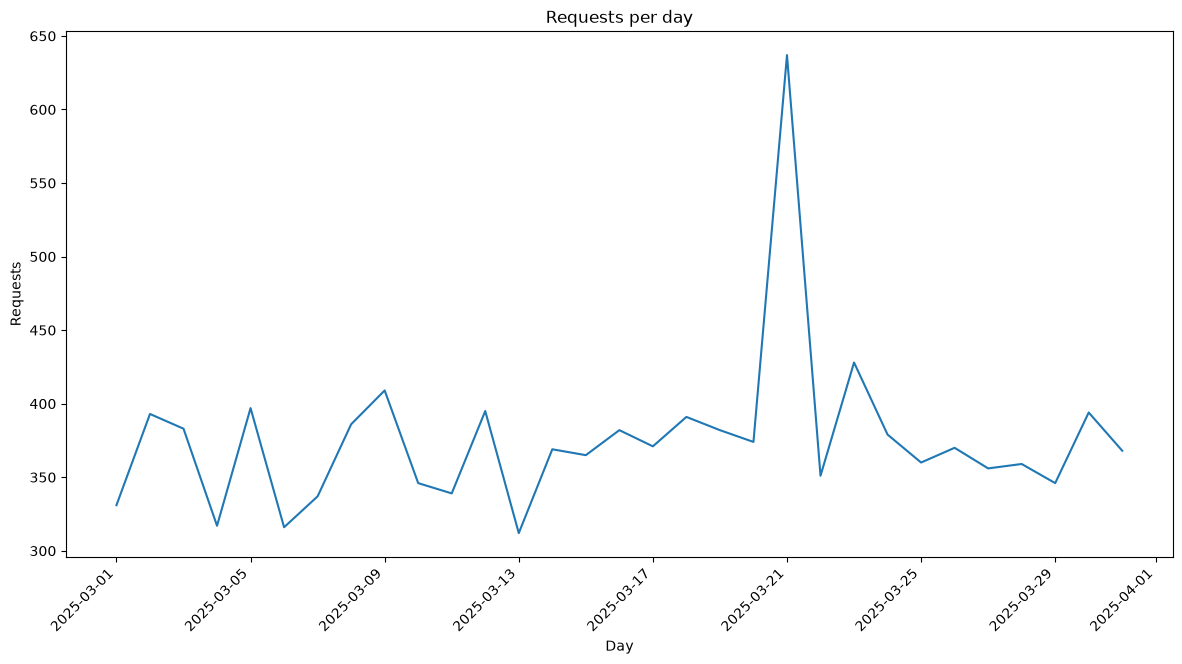

In [36]:
# === Req/día ===
grp = df.groupby(df['ts'].dt.date).size()
plt.figure(figsize=(12, 6))
grp.plot(kind='line')
display_plot("Requests per day", "Day", "Requests", "req_per_day.png")

Figura guardada en: /Users/uoc/Developer/PR1_Astudillo_Soriano_Johnny/resultados/figuras/heatmap.png


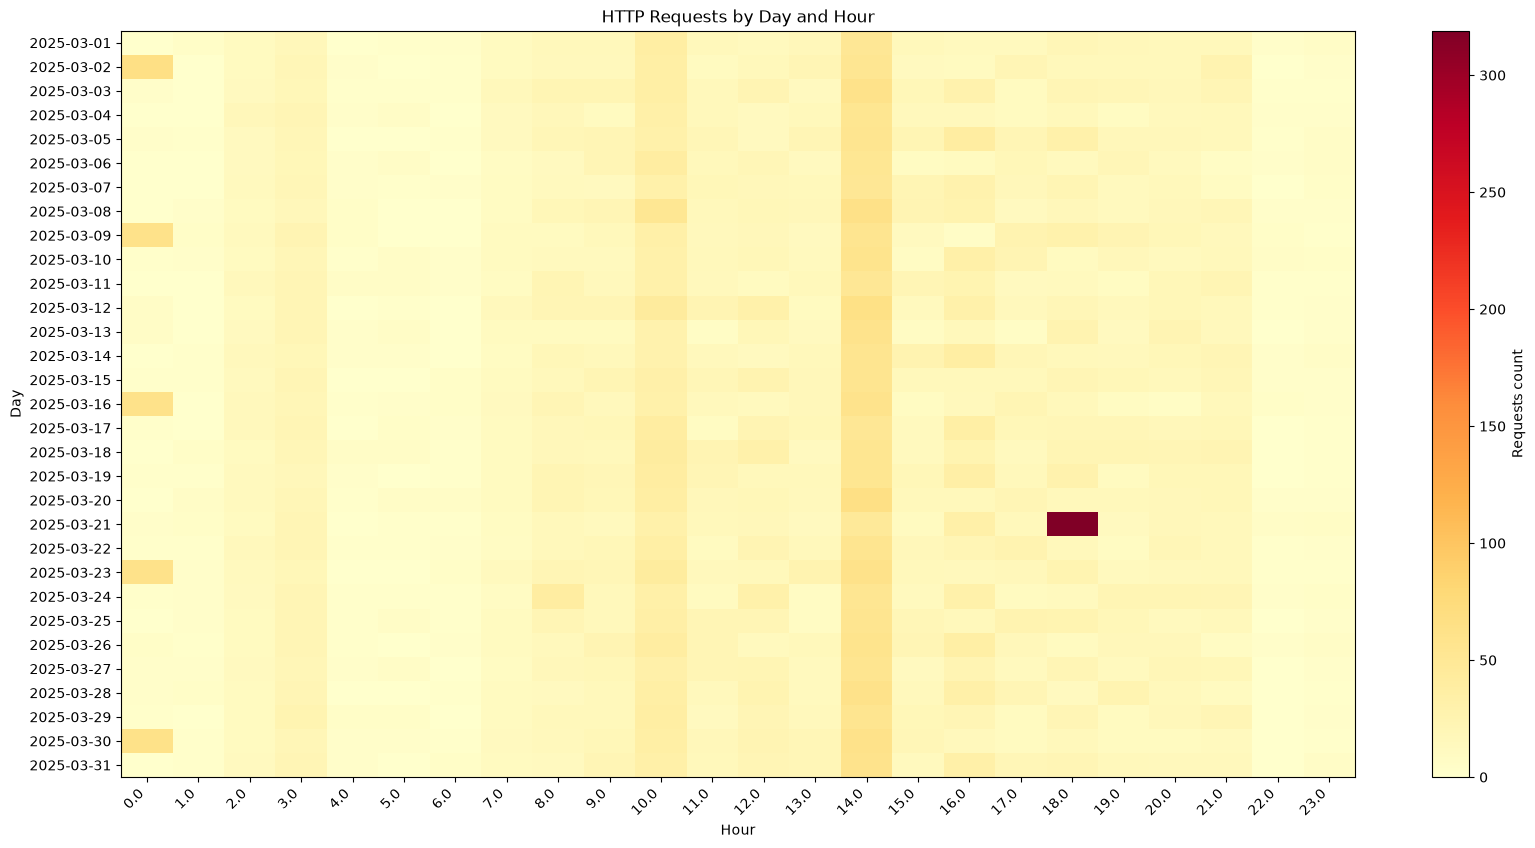

In [37]:
# === heatmap hora×día ===
data = df.groupby(['day', 'hour']).size().unstack(fill_value=0)

plt.figure(figsize=(16, 8))

plt.imshow(
    data,
    cmap='YlOrRd',
    aspect='auto',
    interpolation='nearest'
)

plt.colorbar(label='Requests count')
display_plot("HTTP Requests by Day and Hour", "Hour", "Day", "heatmap.png", xtics=(range(len(data.columns)), data.columns), yticks=(range(len(data.index)), data.index))

Figura guardada en: /Users/uoc/Developer/PR1_Astudillo_Soriano_Johnny/resultados/figuras/status_class_by_host.png


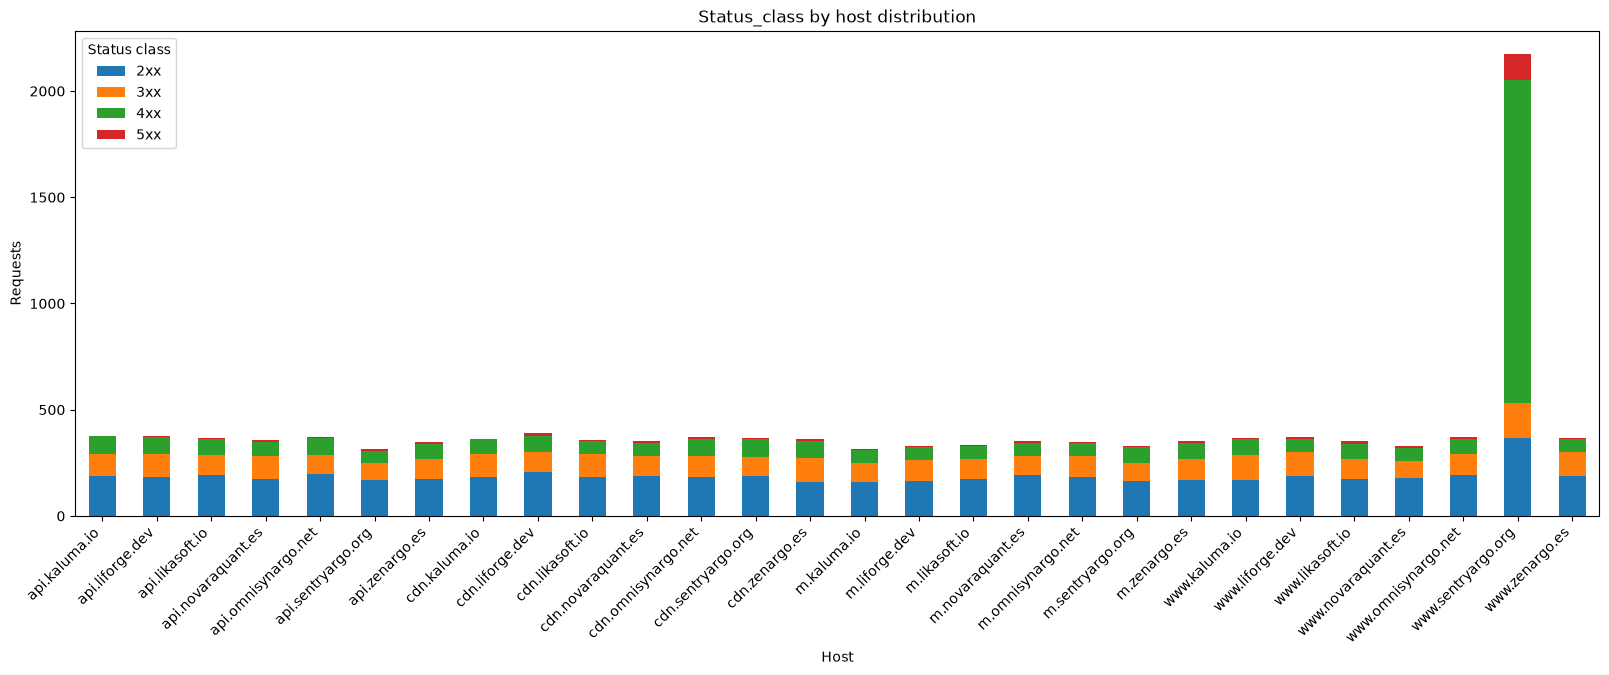

In [38]:
status_host = pd.crosstab(
    df['host'],
    df['status_class']
)

status_host.plot(
    kind='bar',
    stacked=True,
    figsize=(16, 7),
)

display_plot("Status_class by host distribution", "Host", "Requests", "status_class_by_host.png", legend_title='Status class')

Figura guardada en: /Users/uoc/Developer/PR1_Astudillo_Soriano_Johnny/resultados/figuras/status_class_by_user_agent.png


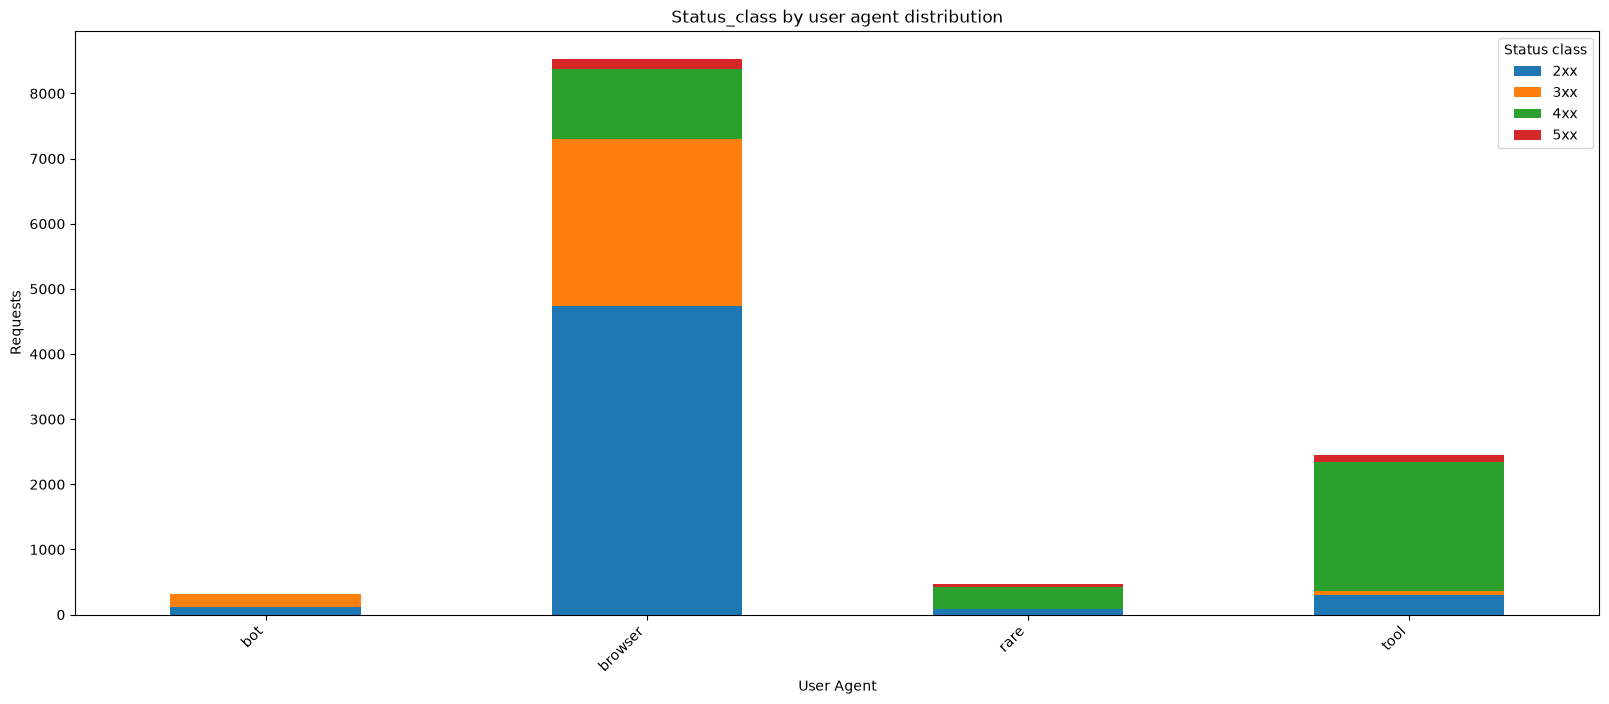

In [39]:
status_ua = pd.crosstab(
    df['ua_family'],
    df['status_class']
)

status_ua.plot(
    kind='bar',
    stacked=True,
    figsize=(16, 7),
)

display_plot("Status_class by user agent distribution", "User Agent", "Requests", "status_class_by_user_agent.png", legend_title='Status class')

Figura guardada en: /Users/uoc/Developer/PR1_Astudillo_Soriano_Johnny/resultados/figuras/top_10_src_ips.png


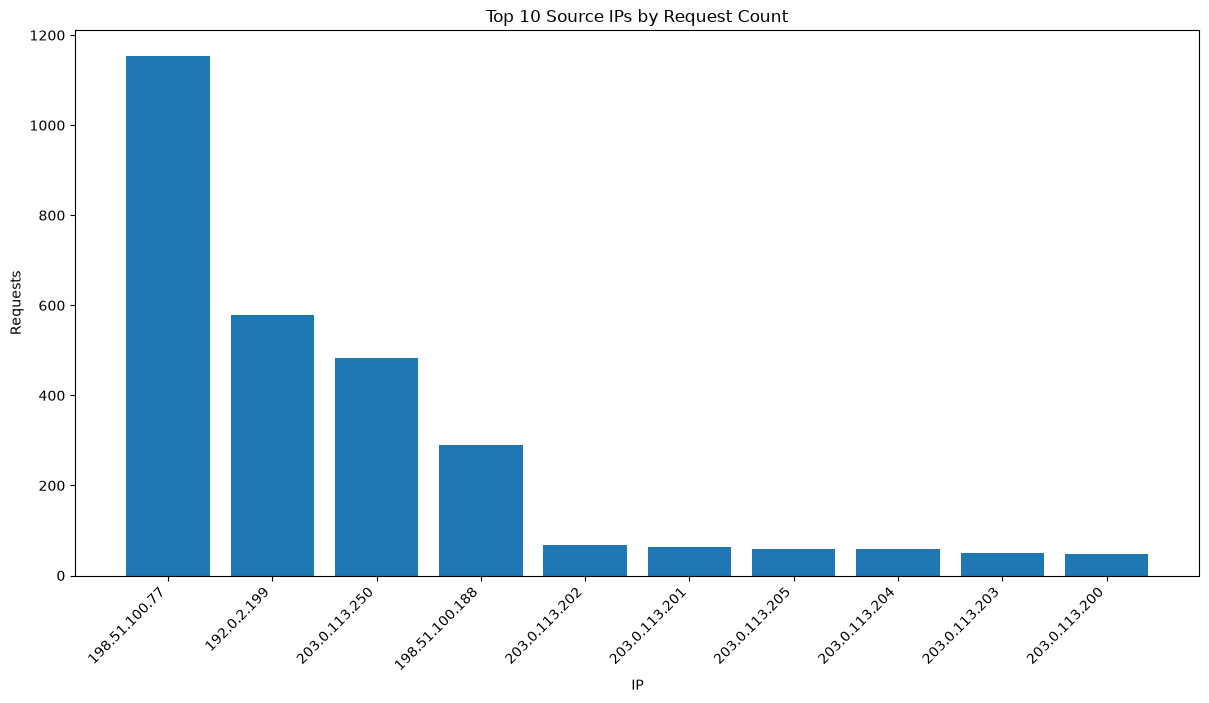

In [40]:
top_10_src_ips = df['src_ip'].value_counts().head(10)
plt.figure(figsize=(12, 6))
plt.bar(top_10_src_ips.index, top_10_src_ips.values)
display_plot("Top 10 Source IPs by Request Count", "IP", "Requests", "top_10_src_ips.png")

Figura guardada en: /Users/uoc/Developer/PR1_Astudillo_Soriano_Johnny/resultados/figuras/top_10_src_ips_by_4xx.png


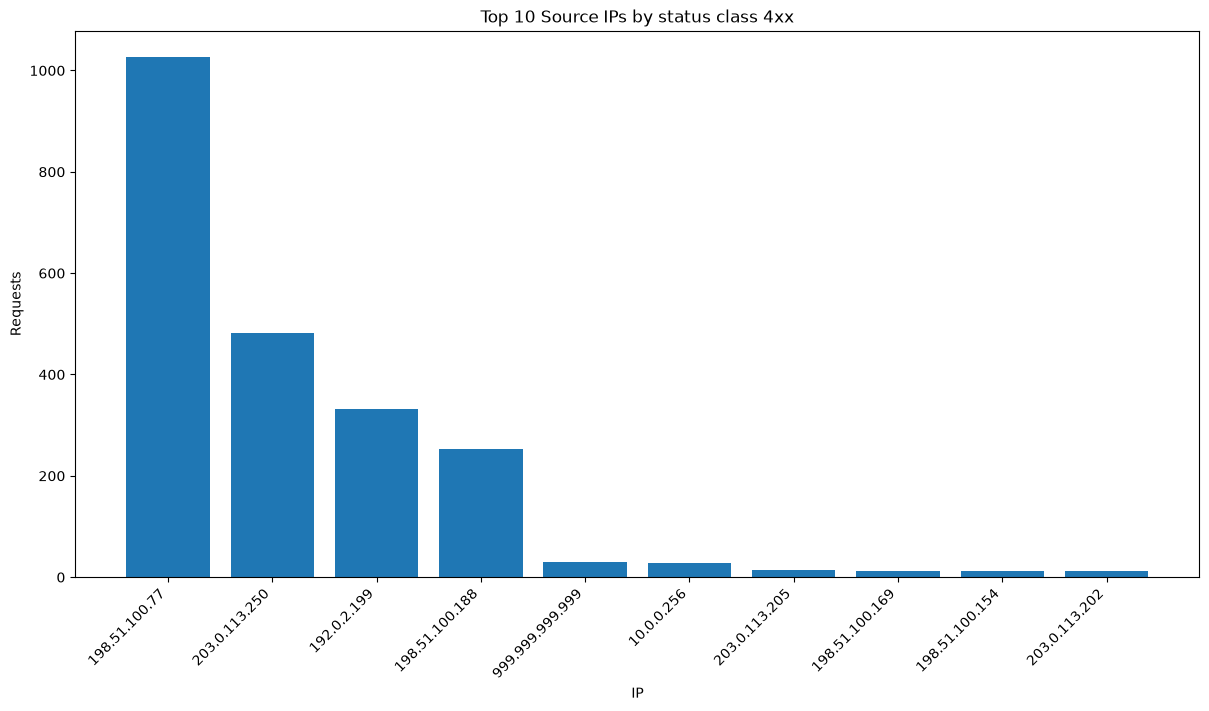

In [41]:
top_10_src_ips_by_4xx = df[df['status_class'] == '4xx']['src_ip'].value_counts().head(10)
plt.figure(figsize=(12, 6))
plt.bar(top_10_src_ips_by_4xx.index, top_10_src_ips_by_4xx.values)
display_plot("Top 10 Source IPs by status class 4xx", "IP", "Requests", "top_10_src_ips_by_4xx.png")

Figura guardada en: /Users/uoc/Developer/PR1_Astudillo_Soriano_Johnny/resultados/figuras/top_10_src_ips_by_5xx.png


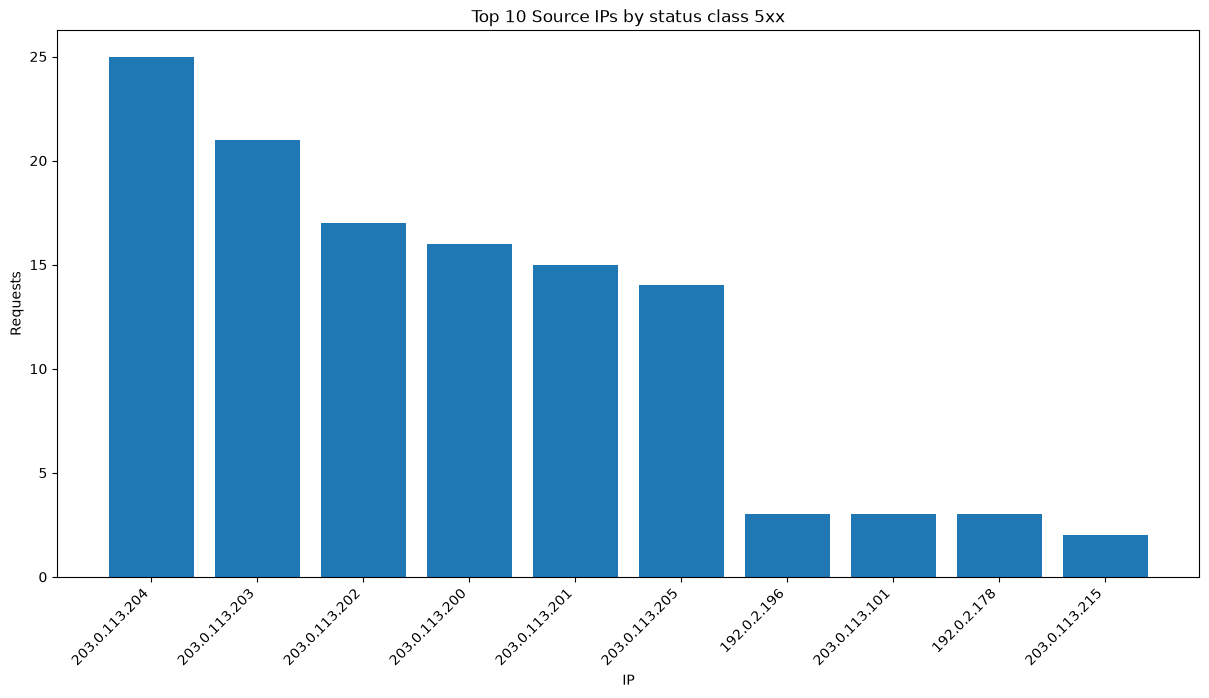

In [42]:
top_10_src_ips_by_5xx = df[df['status_class'] == '5xx']['src_ip'].value_counts().head(10)
plt.figure(figsize=(12, 6))
plt.bar(top_10_src_ips_by_5xx.index, top_10_src_ips_by_5xx.values)
display_plot("Top 10 Source IPs by status class 5xx", "IP", "Requests", "top_10_src_ips_by_5xx.png")

Figura guardada en: /Users/uoc/Developer/PR1_Astudillo_Soriano_Johnny/resultados/figuras/top_10_src_ips_by_404.png


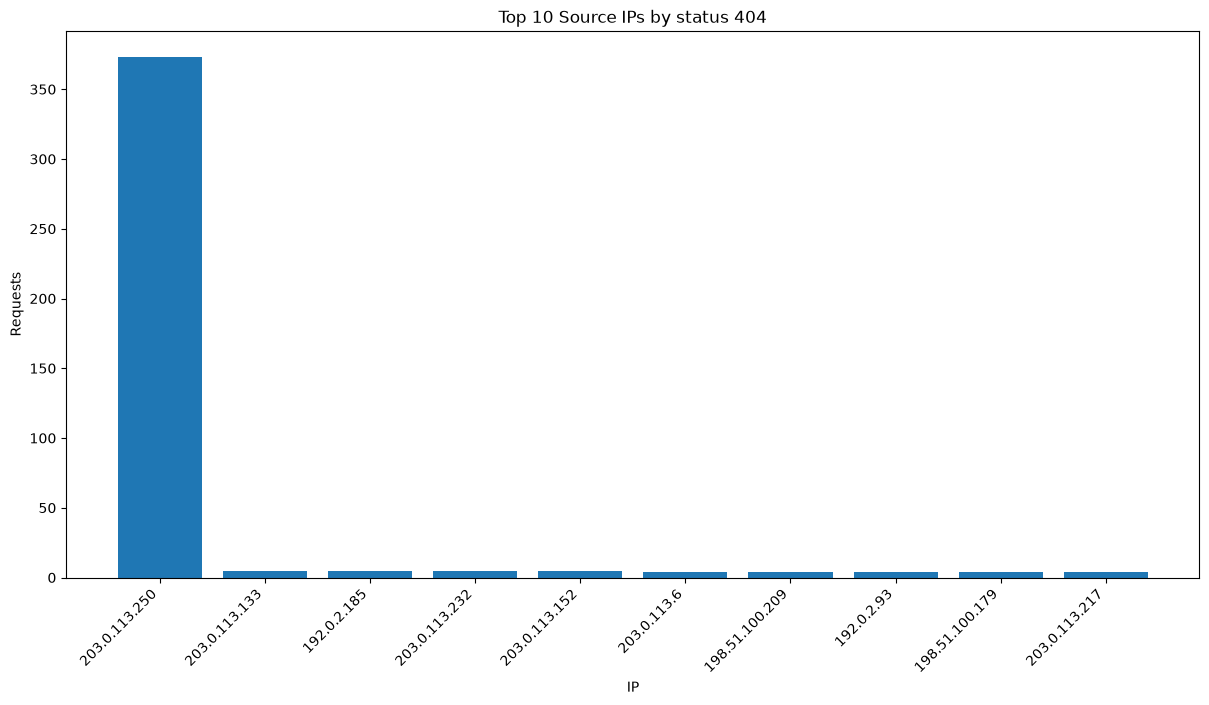

In [43]:
top_10_src_ips_by_404 = df[df['status'] == 404]['src_ip'].value_counts().head(10)
plt.figure(figsize=(12, 6))
plt.bar(top_10_src_ips_by_404.index, top_10_src_ips_by_404.values)
display_plot("Top 10 Source IPs by status 404", "IP", "Requests", "top_10_src_ips_by_404.png")

Figura guardada en: /Users/uoc/Developer/PR1_Astudillo_Soriano_Johnny/resultados/figuras/top_10_url_paths.png


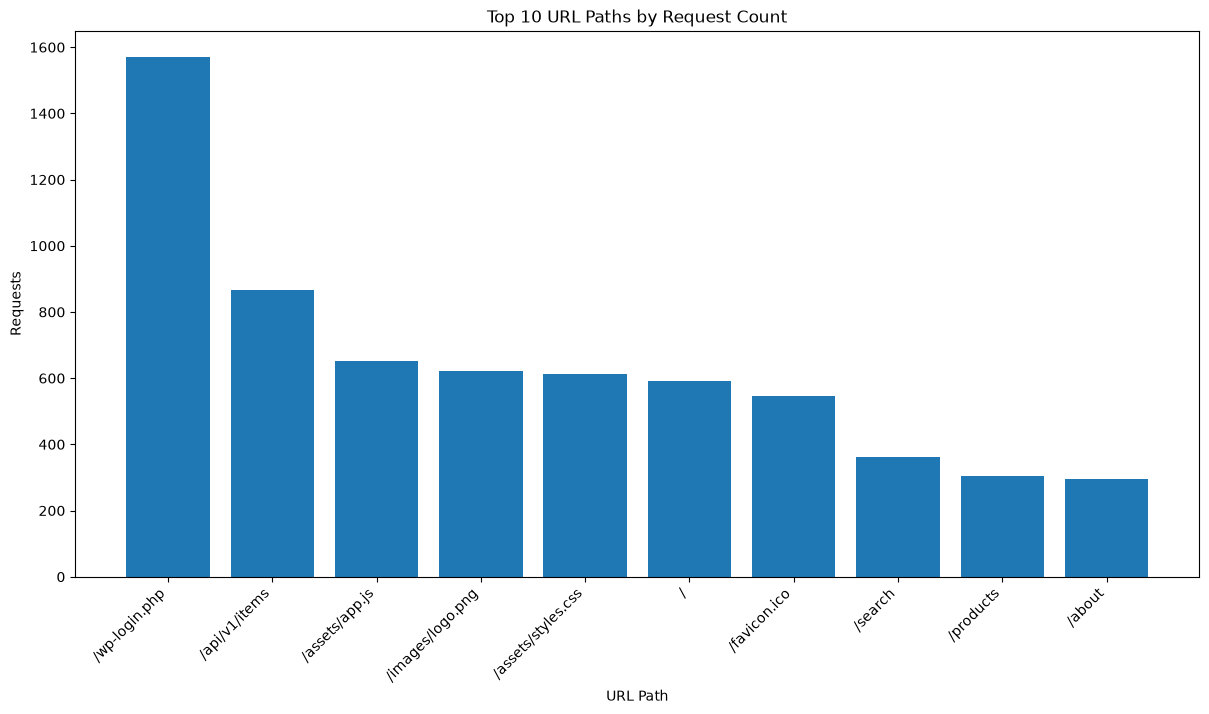

In [44]:
top_10_url_paths = df['url_path'].value_counts().head(10)
plt.figure(figsize=(12, 6))
plt.bar(top_10_url_paths.index, top_10_url_paths.values)
display_plot("Top 10 URL Paths by Request Count", "URL Path", "Requests", "top_10_url_paths.png")

Figura guardada en: /Users/uoc/Developer/PR1_Astudillo_Soriano_Johnny/resultados/figuras/top_10_user_agents.png


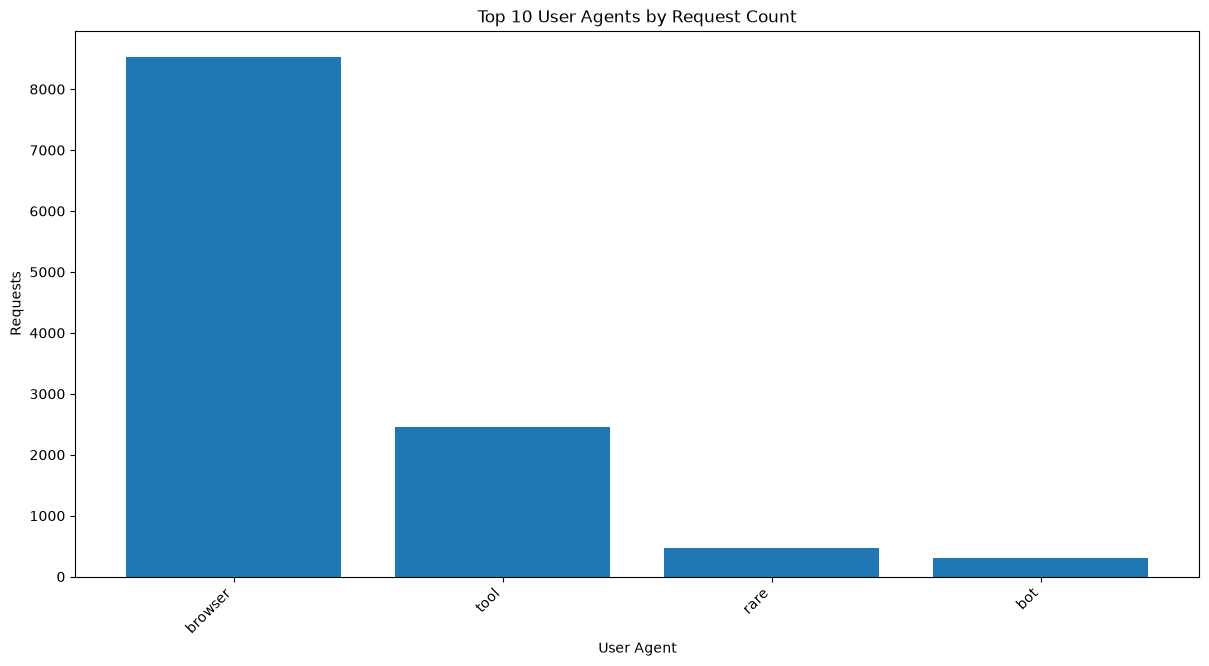

In [45]:
top_10_user_agents = df['ua_family'].value_counts().head(10)
plt.figure(figsize=(12, 6))
plt.bar(top_10_user_agents.index, top_10_user_agents.values)
display_plot("Top 10 User Agents by Request Count", "User Agent", "Requests", "top_10_user_agents.png")

Figura guardada en: /Users/uoc/Developer/PR1_Astudillo_Soriano_Johnny/resultados/figuras/response_time_distribution.png


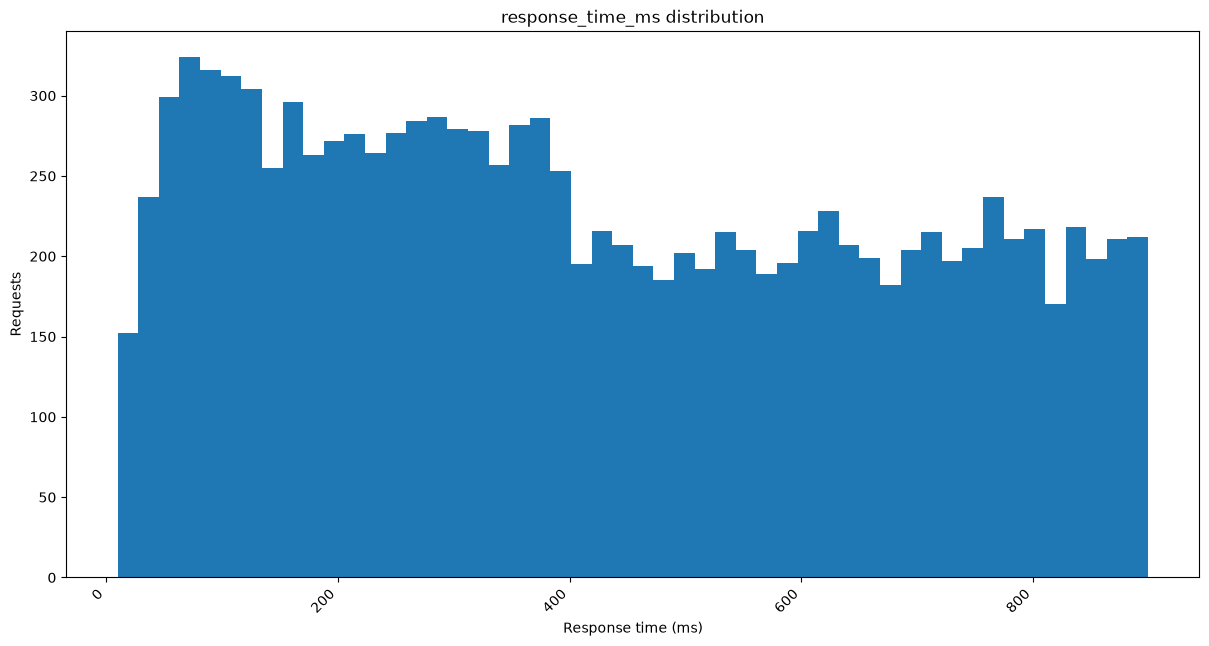

In [46]:
response_times = df['response_time_ms'].dropna()

plt.figure(figsize=(12, 6))
plt.hist(response_times, bins=50)

display_plot("response_time_ms distribution", "Response time (ms)", "Requests", "response_time_distribution.png")

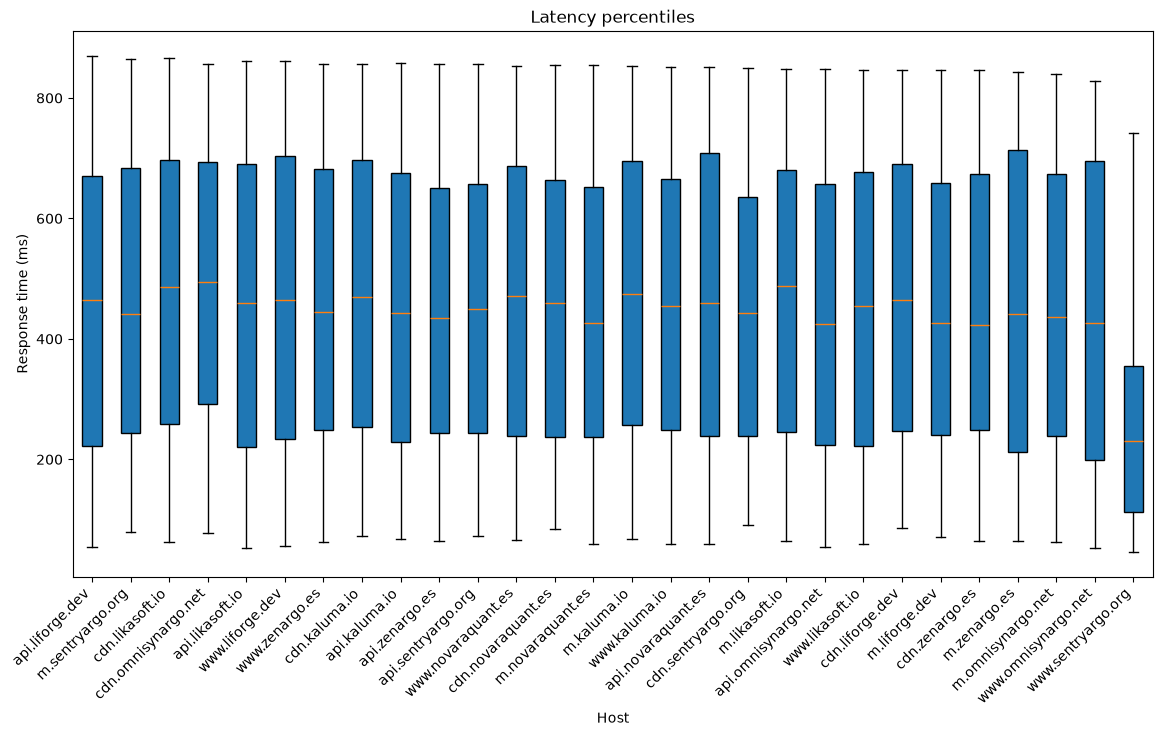

In [47]:
host_order = df.groupby('host')['response_time_ms'].quantile(0.95).sort_values(ascending=False).index
data_by_host = [df[df['host'] == host]['response_time_ms'].dropna() for host in host_order]

plt.figure(figsize=(12, 6))

plt.boxplot(data_by_host, tick_labels=host_order, whis=[5, 95], showfliers=False, patch_artist=True)

display_plot("Latency percentiles", "Host", "Response time (ms)")

Figura guardada en: /Users/uoc/Developer/PR1_Astudillo_Soriano_Johnny/resultados/figuras/bytes_sent_by_type.png


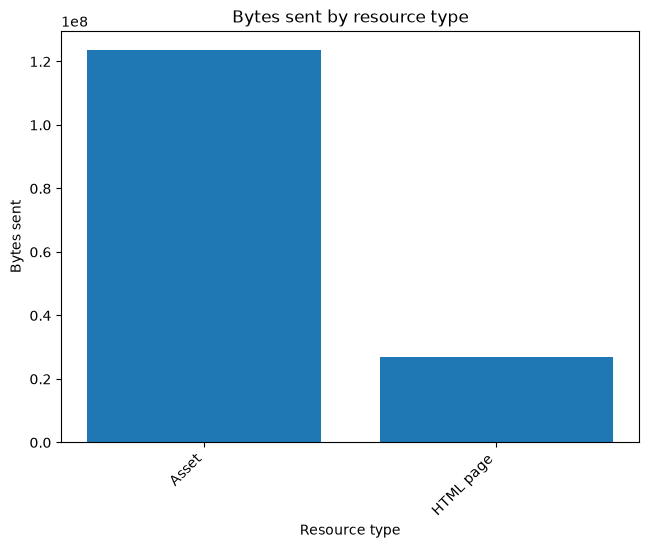

In [48]:
df['resource_type'] = np.where(df['is_asset'], 'Asset', 'HTML page')

bytes_by_type = df.groupby('resource_type')['bytes_sent_num'].sum()


plt.bar(bytes_by_type.index, bytes_by_type.values)

display_plot("Bytes sent by resource type", "Resource type", "Bytes sent", "bytes_sent_by_type.png")

In [49]:
df['status_class'].isin(["4xx", "5xx"])

0         True
1        False
2        False
3        False
4         True
         ...  
11770    False
11771    False
11772    False
11773    False
11774     True
Name: status_class, Length: 11775, dtype: bool

<Figure size 1200x600 with 0 Axes>

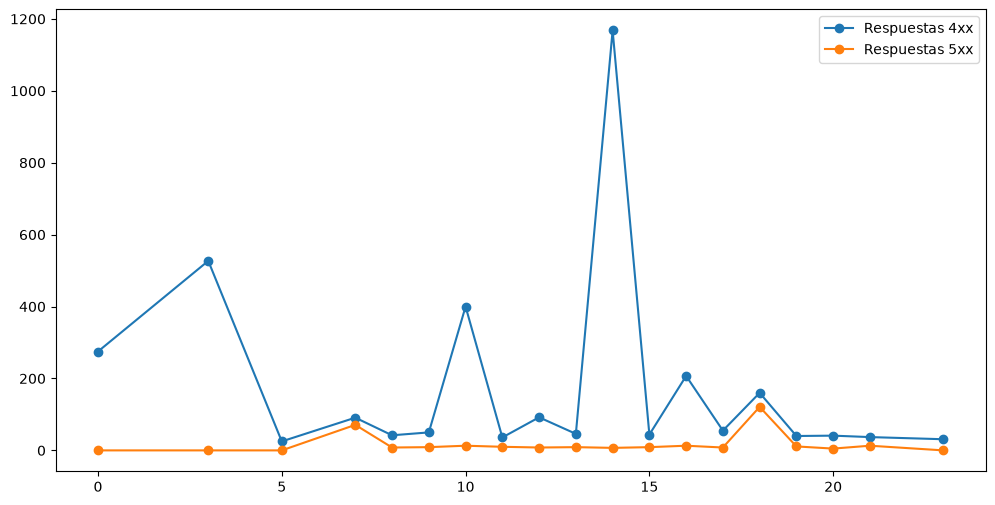

In [50]:

df_errors = df[df['status_class'].isin(['4xx', '5xx'])]

error_counts = pd.crosstab(df_errors['hour'], df_errors['status_class']).reindex(columns=['4xx', '5xx'], fill_value=0)

plt.figure(figsize=(12, 6))

plt.figure(figsize=(12, 6))

if '4xx' in error_counts.columns:
    plt.plot(error_counts.index, error_counts['4xx'], label='Respuestas 4xx', marker='o')
if '5xx' in error_counts.columns:
    plt.plot(error_counts.index, error_counts['5xx'], label='Respuestas 5xx', marker='o')

plt.legend()

plt.show()

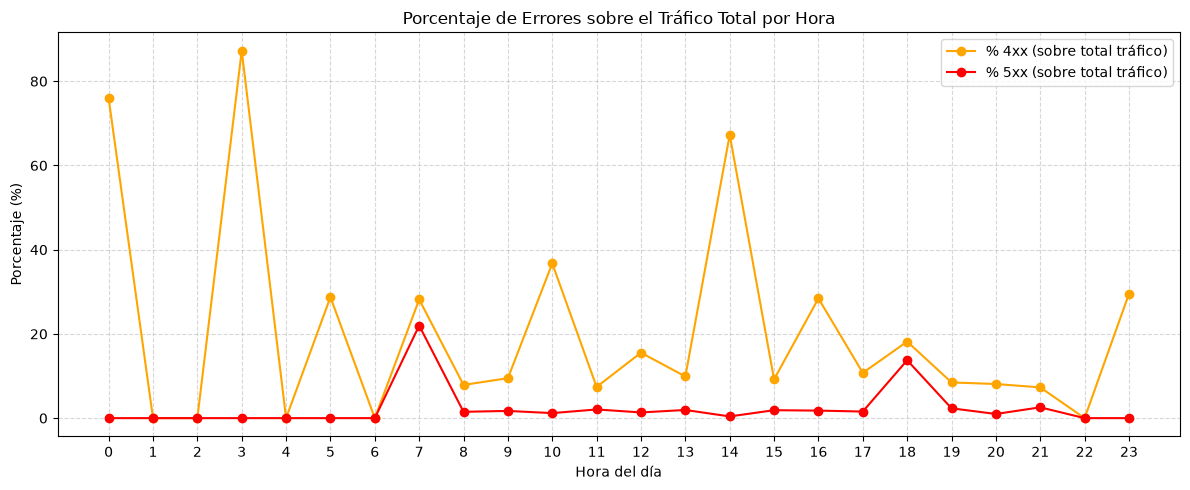

In [51]:
total_req_por_hora = df.groupby('hour').size()

errores_por_hora = pd.crosstab(df['hour'], df['status_class'])

pct_sobre_total = errores_por_hora.div(total_req_por_hora, axis=0) * 100

plt.figure(figsize=(12, 5))
if '4xx' in pct_sobre_total.columns:
    plt.plot(pct_sobre_total.index, pct_sobre_total['4xx'], label='% 4xx (sobre total tráfico)', marker='o', color='orange')
if '5xx' in pct_sobre_total.columns:
    plt.plot(pct_sobre_total.index, pct_sobre_total['5xx'], label='% 5xx (sobre total tráfico)', marker='o', color='red')

plt.title('Porcentaje de Errores sobre el Tráfico Total por Hora')
plt.xlabel('Hora del día')
plt.ylabel('Porcentaje (%)')
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


---
## Etapa D — Detección de patrones y campañas (reglas + evidencias)

Genera `resultados/eventos_flagged.csv` con cabecera:  
`event_id,ts,src_ip,host,url_path,status,attack_type,rule,evidence,severity`

**Campañas a detectar (una función por campaña):**
- Scanner 404/403 diario (~03:05).
- Fuerza bruta a WordPress (~14:10; domingo 00:00 extra).
- SQLi (lun/mié/vie ~16:20).
- LFI/Traversal (mar/jue ~05:45).
- XSS (diario ~12:30).
- Command injection (días alternos ~18:05).
- Rate limiting 429 (diario 10:00).
- Micro‑DDoS (21‑Mar 18:47–18:48).

**Estructura sugerida:** cada función devuelve **un DataFrame** con las columnas requeridas.


In [61]:
from IPython.display import display

SENSITIVE_PATHS = [
    '/admin',
    '/administrator',
    '/wp-admin',
    '/wp-login.php',
    '/phpmyadmin',
    '/.env',
    '/.git',
    '/config',
    '/backup',
    '/login',
    '/api/admin'
]

OUTPUT_COLUMNS = [
    'event_id',
    'ts',
    'src_ip',
    'host',
    'url_path',
    'status',
    'attack_type',
    'rule',
    'evidence',
    'severity'
]


def build_event(row, attack_type, rule, evidence, severity):

    return {
        'event_id': row['event_id'],
        'ts': row['ts'],
        'src_ip': row['src_ip'],
        'host': row['host'],
        'url_path': row['url_path'],
        'status': row['status'],
        'attack_type': attack_type,
        'rule': rule,
        'evidence': evidence,
        'severity': severity
    }


def get_sliding_windows(df: pd.DataFrame, size='120s', min_requests=5) -> list[pd.DataFrame]:
    """
    Return sliding windows for the records in the given pd.DataFrame.

    Parameters
    ----------
    df: pd.DataFrame
        DataFrame to extract sliding windows from.
    size: str
        Windows size using %s format.
    
    """
    # sort records by timestamp
    df = df.sort_values('ts')

    windows = []
    times = df['ts'].tolist()
    delta = pd.Timedelta(size)

    for i, start in enumerate(times):
        end = start + delta
        j = i

        while j < len(times) and times[j] <= end:
            j += 1

        w = df.iloc[i:j]

        # Barrage filter. Do not consider windows if they have less than min_requests requests
        if len(w) >= min_requests:
            windows.append(w)

    return windows


def detect_scanner(df: pd.DataFrame) -> pd.DataFrame:
    """
    Detect any requests were made against sensible endpoints from the same IP at any moment.

    Parameters
    ----------
    df: pd.DataFrame
        DataFrame with the data to analyze.
    
    Returns
    -------
    pd.DataFrame: DataFrame with the parameters for the eventos_flagged.csv file.
    """

    suspicious = df[
        df['url_path'].str.lower().apply(lambda path: any(path.startswith(p) for p in SENSITIVE_PATHS))
    ]

    events = []

    for _, group in suspicious.groupby('src_ip'):
        windows = get_sliding_windows(group, size='0s', min_requests=1)
        for w in windows:
            endpoints = w['url_path'].unique()
            representative = w.iloc[-1]

            evidence = (
                f"requests={len(w)}; "
                f"unique_endpoints={len(endpoints)}; "
                f"endpoints={list(endpoints)[:10]}"
            )

            events.append(
                build_event(
                    representative,
                    'sensible-endpoints-scanner',
                    'Each requests made against sensitive endpoints',
                    evidence,
                    "high"
                )
            )

    return pd.DataFrame(events, columns=OUTPUT_COLUMNS)


def detect_bruteforce_wp(df: pd.DataFrame) -> pd.DataFrame:
    """
    Detect POST rates to /wp-login.php with average 401 responses from the same IP, host.

    Parameters
    ----------
    df: pd.DataFrame
        DataFrame to extract the events from.
    
    Returns
    -------
    pd.DataFrame: DataFrame with the parameters for the eventos_flagged.csv file.
    """
    suspicious = df[(df['url_path'].str.lower() == '/wp-login.php') & (df['http_method'].str.upper() == 'POST')]

    events = []

    for (ip, host), group in suspicious.groupby(['src_ip', 'host']):

        windows = get_sliding_windows(group,size='120s', min_requests=5)

        for w in windows:

            total = len(w)

            count_401 = (w['status'] == 401).sum()

            count_success_candidates = (
                w['status'].isin([200, 302]).sum()
            )

            # Filter to ignore regular users incidents
            if count_401 / total < 0.5:
                continue

            representative = w.iloc[-1]

            evidence = (
                f"POST={total}; "
                f"401={count_401}; "
                f"302_200={count_success_candidates}"
                f"day={representative['day']}"
                f"isWeekend={representative["is_weekend"]};"
                f"hour={representative["hour"]};"
            )

            severity = (
                'high' if count_success_candidates > 0 else 'medium'
            )

            events.append(
                build_event(
                    representative,
                    'wordpress-bruteforce',
                    'Multiple POST requests for /wp-login with average 401 responses in less than 2 minutes from the same IP and host',
                    evidence,
                    severity
                )
            )

    return pd.DataFrame(events, columns=OUTPUT_COLUMNS)


REGEX_SQLI = re.compile(r"(?i)(?:union\s+select|or\s+1=1|--|')")


def detect_sqli(df: pd.DataFrame) -> pd.DataFrame:
    """
    Detect SQL-injection attempts over query strings.
    
    Parameters
    ----------
    df: pd.DataFrame
        DataFrame to extract the events from.
    
    Returns
    -------
    pd.DataFrame: DataFrame with the parameters for the eventos_flagged.csv file.
    """
    query = df['query_string'].str.lower()

    pattern_match = query.str.contains(REGEX_SQLI, regex=True, na=False)

    waf_match = df['event_source'].str.lower().eq('waf') & df['waf_rule_id'].str.upper().str.startswith('SQLI-')

    suspicious = df[pattern_match | waf_match]

    events = []

    for _, row in suspicious.iterrows():

        pattern_detected = bool(pattern_match.loc[row.name])
        waf_detected = bool(waf_match.loc[row.name])

        if pattern_detected:
            match = re.search(REGEX_SQLI, query.loc[row.name])
            if match:
                matched_pattern = match.group(0)

        evidence = (
            f"pattern_match={matched_pattern}; "
            f"waf_match={waf_detected}; "
            f"waf_rule={row['waf_rule_id']}"
        )

        events.append(
            build_event(
                row,
                'sql-injection',
                'SQL-injection pattern found and compared against waf_rules',
                evidence,
                'high' if pattern_detected and waf_detected else 'medium'
            )
        )

    return pd.DataFrame(events, columns=OUTPUT_COLUMNS)


REGEX_LFI  = re.compile(r"(?i)(?:\.\./|%2e%2e)")


def detect_lfi_traversal(df: pd.DataFrame) -> pd.DataFrame:
    """
    Detect any LFI vulnerabilities attempts through url_path and validating against WAF rules.
        
    Parameters
    ----------
    df: pd.DataFrame
        DataFrame to extract the events from.
    
    Returns
    -------
    pd.DataFrame: DataFrame with the parameters for the eventos_flagged.csv file.
    """
    payload = (
        df['url_path'] + ' ' + df['query_string']
    ).str.lower()

    pattern_match = payload.str.contains(REGEX_LFI, regex=True, na=False)

    waf_match = (df['waf_rule_id'].str.upper().str.startswith(('LFI-', 'TRAVERSAL-')))

    suspicious = df[pattern_match | waf_match]

    events = []

    for _, row in suspicious.iterrows():

        pattern_detected = bool(pattern_match.loc[row.name])
        waf_detected = bool(waf_match.loc[row.name])

        if pattern_detected:
            match = re.search(REGEX_LFI, payload.loc[row.name])
            if match:
                matched_pattern = match.group(0)

        evidence = (
            f"lfi_pattern={matched_pattern}; "
            f"waf_match={waf_detected}; "
            f"waf_rule={row['waf_rule_id']}"
        )

        events.append(
            build_event(
                row,
                'lfi-traversal',
                'LFI pattern found at requests url_path/query_string',
                evidence,
                'high' if pattern_detected and waf_detected else 'medium'
            )
        )

    return pd.DataFrame(events, columns=OUTPUT_COLUMNS)


REGEX_XSS  = re.compile(r"(?i)(?:<script|onerror=)")


def detect_xss(df: pd.DataFrame) -> pd.DataFrame:
    """
    Detect any XSS vulnerabilities attempts through url_path and validating against WAF rules.
            
    Parameters
    ----------
    df: pd.DataFrame
        DataFrame to extract the events from.
    
    Returns
    -------
    pd.DataFrame: DataFrame with the parameters for the eventos_flagged.csv file.
    """
    payload = (df['url_path'] + ' ' + df['query_string']).str.lower()

    pattern_match = payload.str.contains(REGEX_XSS, regex=True, na=False)

    waf_match = (df['waf_rule_id'].str.upper().str.startswith('XSS-'))

    suspicious = df[pattern_match | waf_match]

    events = []

    for _, row in suspicious.iterrows():

        pattern_detected = bool(pattern_match.loc[row.name])
        waf_detected = bool(waf_match.loc[row.name])

        if pattern_detected:
            match = re.search(REGEX_XSS, payload.loc[row.name])
            if match:
                matched_pattern = match.group(0)

        evidence = (
            f"xss_pattern={matched_pattern}; "
            f"waf_match={waf_detected}; "
            f"ua_family={row['ua_family']}; "
            f"host={row['host']}; "
            f"waf_rule={row['waf_rule_id']}"
        )

        events.append(
            build_event(
                row,
                'xss',
                'XSS pattern found at request url_path/query_string',
                evidence,
                'high' if pattern_detected and waf_detected else 'medium'
            )
        )

    return pd.DataFrame(events, columns=OUTPUT_COLUMNS)


REGEX_CMDI = re.compile(r"(?i)(?:;\s*cat\s*/etc/)")


def detect_cmdi(df: pd.DataFrame) -> pd.DataFrame:
    """
    Detect any Command Injection vulnerabilities attempts through url_path and validating against WAF rules.
                
    Parameters
    ----------
    df: pd.DataFrame
        DataFrame to extract the events from.
    
    Returns
    -------
    pd.DataFrame: DataFrame with the parameters for the eventos_flagged.csv file.
    """
    payload = (df['url_path'] + ' ' + df['query_string']).str.lower()

    pattern_match = payload.str.contains(REGEX_CMDI, regex=True, na=False)

    waf_match = (df['waf_rule_id'].str.upper().str.startswith('CMDI-'))

    suspicious = df[pattern_match | waf_match]

    events = []

    for _, row in suspicious.iterrows():

        pattern_detected = bool(pattern_match.loc[row.name])
        waf_detected = bool(waf_match.loc[row.name])

        if pattern_detected:
            match = re.search(REGEX_CMDI, payload.loc[row.name])
            if match:
                matched_pattern = match.group(0)

        evidence = (
            f"cmdi_pattern={matched_pattern}; "
            f"waf_match={waf_detected}; "
            f"waf_rule={row['waf_rule_id']}"
        )

        events.append(
            build_event(
                row,
                'cmd-injection',
                'Pattern matching a UNIX command found at request url_path/query_string',
                evidence,
                'high' if pattern_detected and waf_detected else 'medium'
            )
        )

    return pd.DataFrame(events, columns=OUTPUT_COLUMNS)


def detect_rate_limit(df: pd.DataFrame) -> pd.DataFrame:
    """
    Detect 429 response peaks at /api/v1/items from the same IP
                    
    Parameters
    ----------
    df: pd.DataFrame
        DataFrame to extract the events from.
    
    Returns
    -------
    pd.DataFrame: DataFrame with the parameters for the eventos_flagged.csv file.
    """
    requests = df[(df['url_path'].str.startswith('/api/v1/items')) & (df['status'] == 429)]

    events = []

    for ip, group in requests.groupby('src_ip'):

        windows = get_sliding_windows(group, size='60s', min_requests=10
        )

        for w in windows:

            representative = w.iloc[-1]

            evidence = (
                f"429_count={len(w)}; "
                f"window=1min; "
                f"endpoint=/api/v1/items"
            )

            events.append(
                build_event(
                    representative,
                    'rate_limit',
                    'D-RATE-001',
                    evidence,
                    'high' if len(w) >= 30 else 'medium'
                )
            )

    return pd.DataFrame(events, columns=OUTPUT_COLUMNS)


def detect_micro_ddos(df: pd.DataFrame) -> pd.DataFrame:
    """
    Micro-brote de 60–120s con req/s altos a mismo host desde múltiples IPs
    y aumento de 5xx/429; devuelve eventos representativos del intervalo.
    """

    df_work = df.copy()
    if not pd.api.types.is_datetime64_any_dtype(df_work['ts']):
        df_work['ts'] = pd.to_datetime(df_work['ts'])

    # 1. Identificación vectorizada de errores HTTP
    error_codes = {429, 500, 501, 502, 503, 504, 505, 507, 508, 509}
    df_work['is_error'] = df_work['status'].isin(error_codes)

    events = []

    for host, group in df_work.groupby('host'):
        group = group.sort_values('ts')

        # 2. Agregación por segundo
        per_second = group.set_index('ts').resample('1s').agg(
            requests=('event_id', 'count'),
            errors=('is_error', 'sum')
        ).fillna(0)

        if per_second.empty:
            continue

        # 3. Métricas en ventana móvil de 60s
        per_second['requests_60s'] = per_second['requests'].rolling('60s').sum()
        per_second['errors_60s'] = per_second['errors'].rolling('60s').sum()
        per_second['error_ratio_60s'] = (
            per_second['errors_60s'] / per_second['requests_60s'].replace(0, np.nan)
        )

        # 4. FILTRADO VECTORIZADO (Evalúa únicamente los segundos problemáticos)
        candidate_mask = (
            (per_second['requests_60s'] >= 1200) &
            (per_second['requests'] >= 20) &
            (per_second['error_ratio_60s'] >= 0.20)
        )
        candidates = per_second[candidate_mask]

        if candidates.empty:
            continue

        # 5. Agrupamiento para evitar alertas duplicadas/solapadas
        last_processed_end = None

        for timestamp, row in candidates.iterrows():
            start_time = timestamp - pd.Timedelta(seconds=59)

            # Si este segundo cae dentro de una ráfaga ya reportada, se omite
            if last_processed_end and start_time < last_processed_end:
                continue

            # Extraer registros exactos del intervalo
            interval = group[(group['ts'] >= start_time) & (group['ts'] <= timestamp)]
            ip_count = interval['src_ip'].nunique()

            if ip_count >= 5:
                representative = interval.iloc[0]  # Primer evento como inicio de la anomalía
                peak_rps = row['requests']
                error_ratio = row['error_ratio_60s']

                evidence = (
                    f"host={host}; "
                    f"requests_60s={int(row['requests_60s'])}; "
                    f"peak_rps={int(peak_rps)}; "
                    f"unique_ips={ip_count}; "
                    f"error_ratio={error_ratio:.2%}; "
                    f"window_start={start_time}; window_end={timestamp}"
                )

                events.append(
                    build_event(
                        representative,
                        'micro_ddos',
                        'D-DDOS-001',
                        evidence,
                        'high'
                    )
                )

                last_processed_end = timestamp

    return pd.DataFrame(events, columns=OUTPUT_COLUMNS)

In [62]:


df_sorted = df.sort_values('ts').reset_index(drop=True)
detections = []
detections += [detect_scanner(df)]
detections += [detect_bruteforce_wp(df)]
detections += [detect_sqli(df)]
detections += [detect_lfi_traversal(df)]
detections += [detect_xss(df)]
detections += [detect_cmdi(df)]
detections += [detect_rate_limit(df)]
#detections += [detect_micro_ddos(df)]

from pandas import concat
flagged = concat(detections, ignore_index=True)
out_csv = OUT_DIR / "eventos_flagged.csv"
flagged.to_csv(out_csv, index=False)
print("Guardado:", out_csv)


Guardado: /Users/uoc/Developer/PR1_Astudillo_Soriano_Johnny/resultados/eventos_flagged.csv



---
## Etapa E — Validación y métricas

**Cruces sugeridos:**  
- `waf_action`/`waf_rule_id` vs tus reglas (por campaña).  
- `ua_family` y `status_class` por campaña.  
- Métricas por campaña: `#eventos`, `#IPs`, `hosts`, `% WAF bloqueos`.

**Pregunta clave:** ¿qué podría generar **falsos positivos** o **falsos negativos** en tus reglas? ¿Cómo lo mitigarías?


In [63]:

# Ejemplo de estructura (no resuelto):
summary = flagged.groupby('attack_type').agg(eventos=('event_id','count'), ips=('src_ip','nunique'), hosts=('host','nunique'))
summary

,eventos,ips,hosts
attack_type,,,
cmd-injection,96,92,28
lfi-traversal,32,32,18
rate_limit,58,1,17
sensible-endpoints-scanner,1995,344,28
sql-injection,195,35,28
wordpress-bruteforce,1170,2,1
xss,62,61,26


In [66]:
# 1. Unir eventos alertados con el dataset original para recuperar atributos de contexto
flagged_full = flagged.merge(
    df[['event_id', 'waf_action', 'waf_rule_id', 'ua_family', 'status_class']], 
    on='event_id', 
    how='left'
)

# -------------------------------------------------------------------------
# PUNTO 21: Métricas Simples por Campaña (attack_type)
# -------------------------------------------------------------------------
summary_metrics = flagged_full.groupby('attack_type').agg(
    num_eventos=('event_id', 'count'),
    num_ips=('src_ip', 'nunique'),
    num_hosts=('host', 'nunique'),
    pct_waf_blocked=(
        'waf_action', 
        lambda x: (x.fillna('').str.lower().isin(['block', 'deny', 'drop'])).mean() * 100
    )
).reset_index()

summary_metrics['pct_waf_blocked'] = summary_metrics['pct_waf_blocked'].round(2)

print("=== MÉTRICAS RESUMEN POR CAMPAÑA ===")
summary_metrics










=== MÉTRICAS RESUMEN POR CAMPAÑA ===


,attack_type,num_eventos,num_ips,num_hosts,pct_waf_blocked
0,cmd-injection,96,92,28,100.00
1,lfi-traversal,32,32,18,100.00
2,rate_limit,58,1,17,0.00
3,sensible-endpoints-scanner,1995,344,28,4.66
4,sql-injection,195,35,28,100.00
5,wordpress-bruteforce,1170,2,1,0.00
6,xss,62,61,26,45.16


In [ ]:
top_ua_per_attack = (
    flagged_full.groupby(['attack_type', 'ua_family'])
    .size()
    .reset_index(name='count')
    .sort_values(['attack_type', 'count'], ascending=[True, False])
    .groupby('attack_type')
    .head(3)  # Muestra los 3 User-Agents más comunes por campaña
)

print("\n=== TOP USER AGENTS POR CAMPAÑA ===")
top_ua_per_attack

In [ ]:
crosstab_status = pd.crosstab(
    flagged_full['attack_type'], 
    flagged_full['status_class'], 
    margins=True, 
    margins_name='Total'
)

print("\n=== CRUCE: ATAQUE VS CLASE DE STATUS HTTP ===")
print(crosstab_status)

In [ ]:
crosstab_waf = pd.crosstab(
    flagged_full['attack_type'], 
    flagged_full['waf_action'].fillna('NO_WAF_ACTION'),
    margins=True, 
    margins_name='Total'
)

print("\n=== CRUCE: ATAQUE VS ACCIÓN WAF ===")
print(crosstab_waf)


---
## Etapa F — Informe (máx. 5 páginas, PDF)

**Estructura sugerida:**
1. **Resumen ejecutivo** (≤ 10 líneas).
2. **Metodología de limpieza** (decisiones y su impacto).
3. **EDA** (2–3 insights apoyados con figuras).
4. **Detecciones por campaña**: 1 subsección por campaña con **regla**, **métrica** y **gráfico**.
5. **Conclusiones y acciones recomendadas** (WAF, rate limit, monitoreo, *honeypots*, etc.).
6. **(Opcional)** Idea de IA para futuras mejoras (features por IP/día, IsolationForest/DBSCAN, validación).

> Exporta las figuras en `resultados/figuras/` y referencia los nombres en el PDF.



---
## Checklist de entrega

- [x] Notebook ejecuta sin errores (una vez completado).
- [x] Figuras guardadas en `resultados/figuras/` con títulos/ejes/leyendas legibles.
- [x] `resultados/eventos_flagged.csv` con columnas: `event_id,ts,src_ip,host,url_path,status,attack_type,rule,evidence,severity`.
- [x] Informe PDF (≤ 5 páginas) con narrativa clara y evidencias.
- [x] `requirements.txt` o `environment.yml`.
- [x] Estructura de carpetas respetada.
